# Lévy processes and random walks: a companion to Sec. I, II and II.A

This notebook is background material for `Manuscript/main.tex` Sec. I
("Deterministic and stochastic fouling framework", `sec:theory`), Sec. II
("Stochastic formulation of Linear Fouling Models", `sec:stochastic_formulation`)
and Sec. II.A ("Event spectrum and effective number of events", `sec:activity`).

The route taken here is deliberately linear and cumulative, building one
expectation at a time:

- **Part A** starts with the plain discrete-time **random walk**: its mean,
  its variance, and the two limit theorems everyone learns first — the Law
  of Large Numbers (LLN) and the Central Limit Theorem (CLT).
- **Part B** moves to continuous time: **Lévy processes**, with and without
  a drift term. We redo the *exact same* four questions (mean, variance,
  LLN, CLT) and show they carry over essentially unchanged — a Lévy
  process is, in a precise sense, a random walk indexed by continuous time.
- **Part C** specializes to **subordinators**: the non-negative,
  non-decreasing Lévy processes, which is the only kind that can represent
  a fouling deposit (it can only grow).
- **Part D** uses everything built in A–C to state, *before looking at the
  paper's result*, what the CLT should predict for fouling aggregation —
  and then checks that prediction numerically against Sec. II.D.

By the end, "Lévy process" should feel like nothing more exotic than "a
random walk, but defined at every instant of time instead of only at
integer ticks, with a possibly non-Gaussian but still well-behaved step
law.\"

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats

INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
COL = {"CPP": "#2a78d6", "Gamma": "#eb6834", "BM": "#1baf7a", "RW": "#8a5fd1"}
plt.rcParams.update({
    "font.size": 8.5, "axes.labelsize": 8.5, "axes.titlesize": 9, "legend.fontsize": 7.5,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.5,
    "axes.axisbelow": True, "lines.linewidth": 1.1, "pdf.fonttype": 42, "figure.dpi": 150,
    "legend.frameon": False,
})

# fouling-model parameters, used from Part C onward (same as the companion notebook)
m, c, tau0 = 1.0, 2.0, 1.0
t_c = c**2 * tau0
ell = c**2 * m * tau0
beta = ell / 2.0
lam_rate = 2.0 / t_c
s = c * m * np.sqrt(tau0)
theta_scale = m * c**2
print(f"fouling-model parameters: m={m}, c={c}, t_c={t_c}, activity r={lam_rate}, s={s}")

fouling-model parameters: m=1.0, c=2.0, t_c=4.0, activity r=0.5, s=2.0


## Part A — Random walks: mean, variance, LLN, CLT

A random walk is a running sum of i.i.d. steps, $S_n = X_1+\dots+X_n$. We
use $X_i\sim\mathrm{Exponential}(1)$ as the running example throughout
Part A: one-sided (like a deposition event), mean $\mu=1$, variance
$\sigma^2=1$. Everything in this section is completely standard
probability theory — no fouling yet — but every piece of it reappears,
essentially unchanged, once we move to continuous time in Part B.

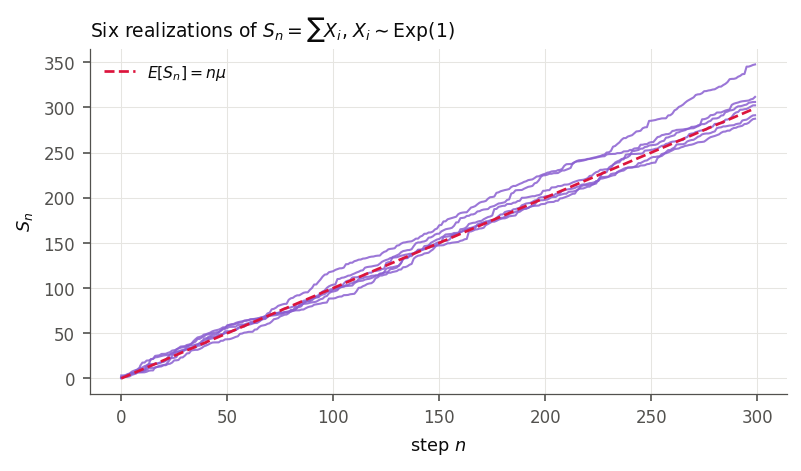

In [2]:
rng = np.random.default_rng(0)
n_steps = 300
steps = rng.exponential(1.0, size=(6, n_steps))
paths = np.cumsum(steps, axis=1)

fig, ax = plt.subplots(figsize=(5.4, 3.2))
for p in paths:
    ax.plot(p, lw=1.0, alpha=0.85, color=COL["RW"])
ax.plot(np.arange(n_steps), np.arange(n_steps) * 1.0, color="crimson", ls="--", lw=1.3, label=r"$E[S_n]=n\mu$")
ax.set_xlabel("step $n$"); ax.set_ylabel("$S_n$")
ax.set_title(r"Six realizations of $S_n=\sum X_i$, $X_i\sim\mathrm{Exp}(1)$", loc="left", fontsize=9)
ax.legend(fontsize=7.5)
fig.tight_layout()
plt.show()

### A.1 Mean and variance of $S_n$

For i.i.d. steps with $\mathbb E[X_i]=\mu$ and $\mathrm{Var}[X_i]=\sigma^2$,
$$\mathbb E[S_n]=n\mu,\qquad \mathrm{Var}[S_n]=n\sigma^2 .$$
Both grow **linearly in $n$**. This is the single most important fact to
carry forward: it is exactly the structure that reappears as
$\mathbb E[D(t)]=mt$, $\mathrm{Var}[D(t)]=s^2t$ in Sec. II
(Eq. `eq:deposition_mean`, `eq:deposition_variance_rate`), with $n\to t$.

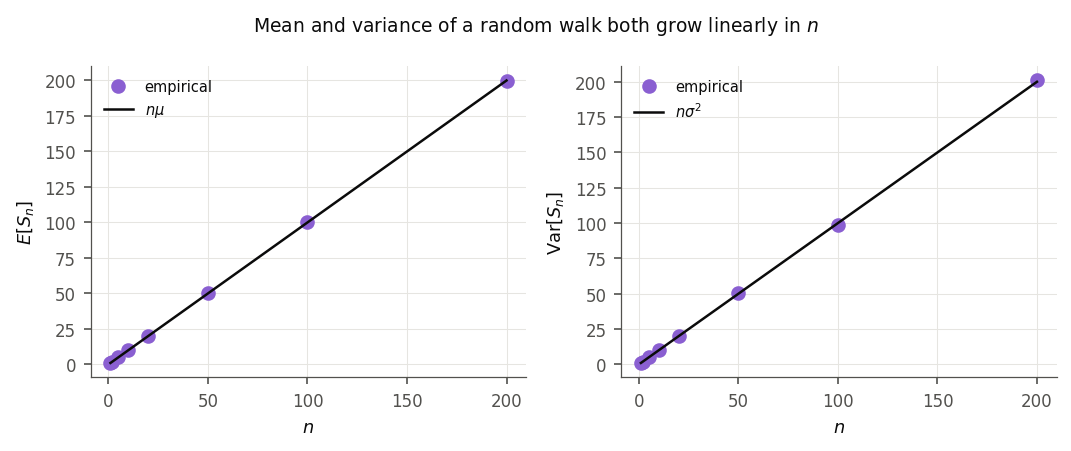

In [3]:
n_list = np.array([1, 2, 5, 10, 20, 50, 100, 200])
n_mc = 20000
rng = np.random.default_rng(1)
emp_mean, emp_var = [], []
for n in n_list:
    x = rng.exponential(1.0, size=(n_mc, n))
    S = x.sum(axis=1)
    emp_mean.append(S.mean())
    emp_var.append(S.var())

fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.0))
axes[0].plot(n_list, emp_mean, "o", color=COL["RW"], label="empirical")
axes[0].plot(n_list, n_list * 1.0, color=INK, lw=1.2, label=r"$n\mu$")
axes[0].set_xlabel("$n$"); axes[0].set_ylabel(r"$E[S_n]$"); axes[0].legend(fontsize=7)
axes[1].plot(n_list, emp_var, "o", color=COL["RW"], label="empirical")
axes[1].plot(n_list, n_list * 1.0, color=INK, lw=1.2, label=r"$n\sigma^2$")
axes[1].set_xlabel("$n$"); axes[1].set_ylabel(r"$\mathrm{Var}[S_n]$"); axes[1].legend(fontsize=7)
fig.suptitle("Mean and variance of a random walk both grow linearly in $n$", fontsize=9)
fig.tight_layout()
plt.show()

### A.2 Law of Large Numbers

$S_n/n \to \mu$ almost surely as $n\to\infty$. Dividing by $n$ kills the
$\sqrt n$-sized fluctuations relative to the $n$-sized mean, leaving a
deterministic number.

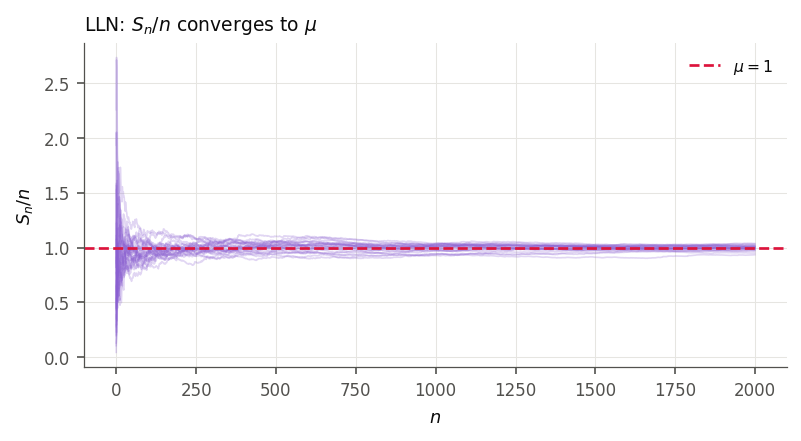

In [4]:
rng = np.random.default_rng(2)
n_steps = 2000
n_show = 25
x = rng.exponential(1.0, size=(n_show, n_steps))
running_mean = np.cumsum(x, axis=1) / np.arange(1, n_steps + 1)

fig, ax = plt.subplots(figsize=(5.4, 3.0))
for p in running_mean:
    ax.plot(p, color=COL["RW"], alpha=0.25, lw=0.8)
ax.axhline(1.0, color="crimson", ls="--", lw=1.3, label=r"$\mu=1$")
ax.set_xlabel("$n$"); ax.set_ylabel(r"$S_n/n$")
ax.set_title("LLN: $S_n/n$ converges to $\\mu$", loc="left", fontsize=9)
ax.legend(fontsize=7.5)
fig.tight_layout()
plt.show()

### A.3 Central Limit Theorem

$(S_n-n\mu)/(\sigma\sqrt n) \to \mathcal N(0,1)$ in distribution. Unlike the
LLN (which only needs a finite mean), the CLT needs a finite variance, and
it says something **universal**: the limit is always the same standard
Gaussian, regardless of the shape of the step law. We check this with
three visibly different step laws (exponential, uniform, and a discrete
two-point law) — all converge to the same bell curve once enough steps are
summed.

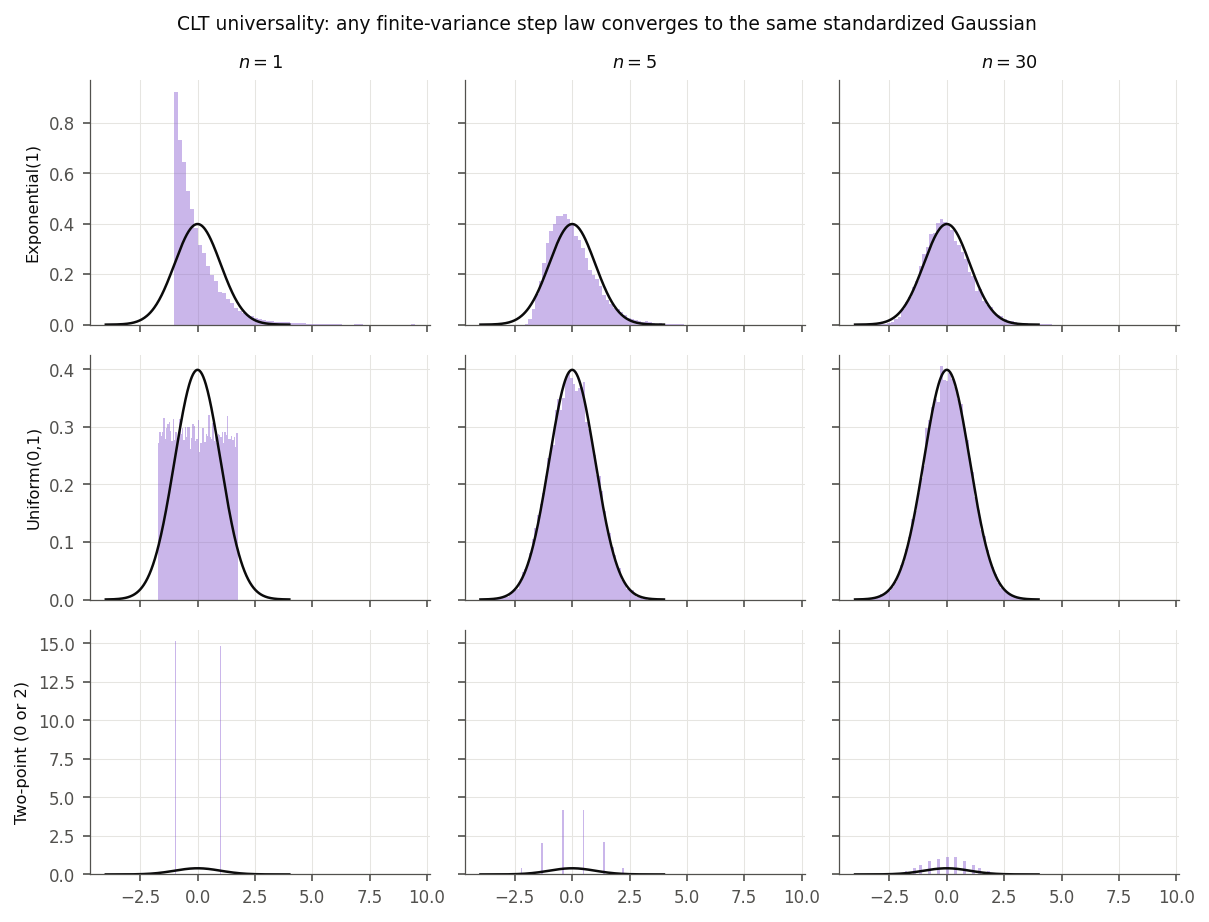

In [5]:
rng = np.random.default_rng(3)
laws = {
    "Exponential(1)": lambda n, size: rng.exponential(1.0, size=(size, n)),
    "Uniform(0,1)": lambda n, size: rng.uniform(0.0, 1.0, size=(size, n)),
    "Two-point (0 or 2)": lambda n, size: rng.choice([0.0, 2.0], size=(size, n)),
}
ns = [1, 5, 30]

fig, axes = plt.subplots(len(laws), len(ns), figsize=(8.0, 6.2), sharex=True, sharey="row")
xx = np.linspace(-4, 4, 300)
for i, (name, law) in enumerate(laws.items()):
    for j, n in enumerate(ns):
        x = law(n, 20000)
        ssum = x.sum(axis=1)
        s_std = (ssum - ssum.mean()) / ssum.std()
        axes[i, j].hist(s_std, bins=60, density=True, color=COL["RW"], alpha=0.45, edgecolor="none")
        axes[i, j].plot(xx, stats.norm.pdf(xx), color=INK, lw=1.2)
        if i == 0:
            axes[i, j].set_title(f"$n={n}$", fontsize=8.5)
        if j == 0:
            axes[i, j].set_ylabel(name, fontsize=7.8)
fig.suptitle("CLT universality: any finite-variance step law converges to the same standardized Gaussian", fontsize=9)
fig.tight_layout()
plt.show()

(Visual caveat: the "two-point" law lives on a discrete lattice, so its
sums stay visibly grid-like for longer than the continuous laws before the
Gaussian envelope smooths out — a real, well-known effect, not a failure
of convergence.)

**Take-away from Part A, to carry forward:** for *any* random walk with
finite mean and variance, (i) mean and variance grow linearly in $n$; (ii)
dividing by $n$ gives a deterministic limit (LLN); (iii) standardizing by
$\sqrt n$ gives a *universal* Gaussian limit (CLT), regardless of the step
shape. Parts B–D are about replacing "step number $n$" with "elapsed time
$t$," or "number of deposition events," and checking that nothing
essential changes.

## Part B — Lévy processes: with and without drift

A **Lévy process** $D(t)$ is the continuous-time analogue of a random
walk: $D(0)=0$, and increments over disjoint time windows are independent
and stationary (their law depends only on the window length, Sec. II
assumptions (a)–(b)). The Lévy–Khintchine theorem (`eq:levy_khintchine`)
says every such process is built from three independent ingredients — a
deterministic **drift** $b$, an independent **Brownian motion** (variance
rate $\sigma^2$), and an independent **jump part** driven by a measure
$\nu$:
$$D(t) \;=\; bt \;+\; \sigma W(t) \;+\; J(t).$$

We build two concrete examples below, each shown **with and without
drift**, to see exactly what the drift term does (and, just as
importantly, what it does *not* do):

- a **jump-type** process: compound Poisson, $\sigma=0$;
- a **Gaussian-type** process: Brownian motion, $\nu=0$.

Both are Lévy processes; they sit at opposite ends of the triplet.

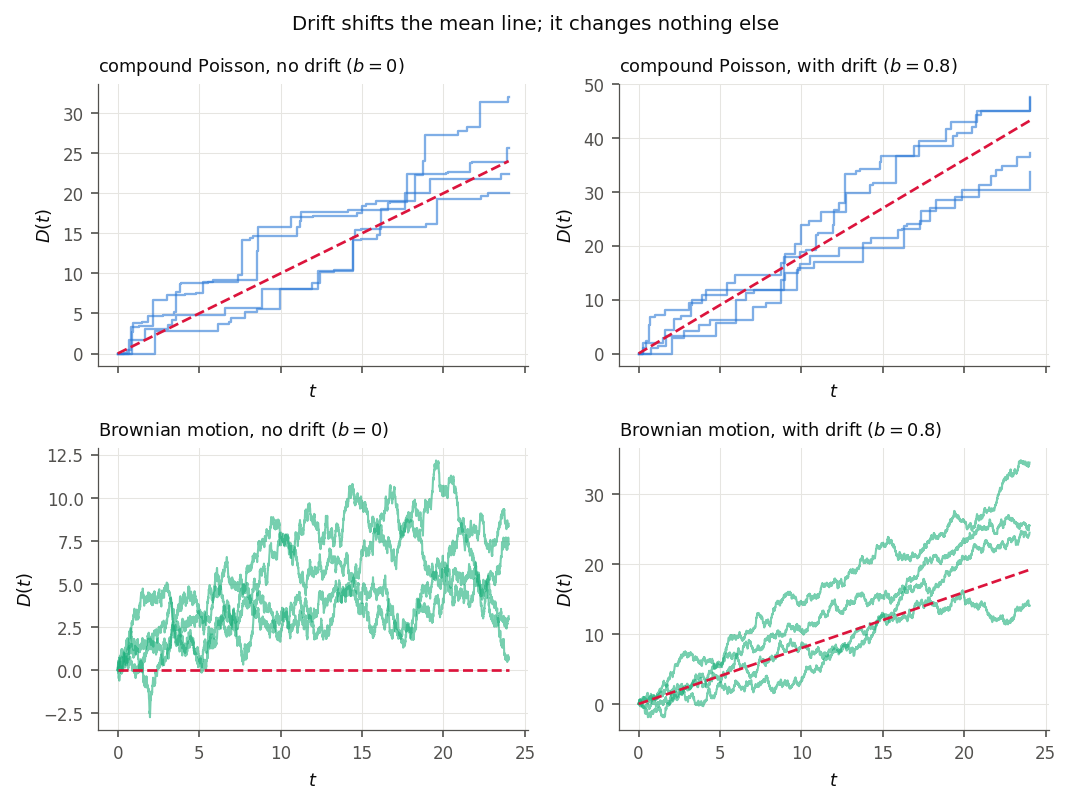

In [6]:
T_demo = 24.0
rng = np.random.default_rng(10)

# compound Poisson, same event law as Part A's exponential steps (mean 1, here beta_demo=1)
beta_demo, lam_demo = 1.0, 1.0
def cpp_path(rng, T, drift=0.0):
    n = rng.poisson(lam_demo * T)
    arr = np.sort(rng.uniform(0, T, size=n))
    sz = rng.exponential(beta_demo, size=n)
    t = np.concatenate(([0.0], arr, [T]))
    y = np.concatenate(([0.0], np.cumsum(sz)))
    y = np.concatenate((y, [y[-1]]))
    return t, y + drift * t

# Brownian motion, matched variance rate sigma^2 = lam_demo*beta_demo^2*2 (CPP's variance rate) for comparability
sigma2_demo = lam_demo * 2 * beta_demo**2
def bm_path(rng, T, drift=0.0, n_steps=4000):
    dt = T / n_steps
    incr = rng.normal(0, np.sqrt(sigma2_demo * dt), size=n_steps)
    t = np.arange(n_steps + 1) * dt
    y = np.concatenate(([0.0], np.cumsum(incr))) + drift * t
    return t, y

fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.4), sharex=True)
rng1 = np.random.default_rng(11)
for ax, drift, label in zip(axes[0], [0.0, 0.8], ["no drift ($b=0$)", "with drift ($b=0.8$)"]):
    for _ in range(4):
        t, y = cpp_path(rng1, T_demo, drift)
        ax.step(t, y, where="post", color=COL["CPP"], alpha=0.6, lw=1.1)
    ax.plot([0, T_demo], [0, (lam_demo * beta_demo + drift) * T_demo], color="crimson", ls="--", lw=1.3)
    ax.set_title(f"compound Poisson, {label}", loc="left", fontsize=8.5)

rng2 = np.random.default_rng(12)
for ax, drift, label in zip(axes[1], [0.0, 0.8], ["no drift ($b=0$)", "with drift ($b=0.8$)"]):
    for _ in range(4):
        t, y = bm_path(rng2, T_demo, drift)
        ax.plot(t, y, color=COL["BM"], alpha=0.6, lw=1.0)
    ax.plot([0, T_demo], [0, drift * T_demo], color="crimson", ls="--", lw=1.3)
    ax.set_title(f"Brownian motion, {label}", loc="left", fontsize=8.5)

for ax in axes.ravel():
    ax.set_xlabel("$t$"); ax.set_ylabel("$D(t)$")
fig.suptitle("Drift shifts the mean line; it changes nothing else", fontsize=9.5)
fig.tight_layout()
plt.show()

Both rows show the same thing: adding a drift $b$ tilts the dashed mean
line, and nothing about the *shape* of the fluctuations around it changes.
This is a completely general fact: the drift term in the Lévy–Khintchine
triplet only ever shifts $\mathbb E[D(t)]$; it leaves $\mathrm{Var}[D(t)]$,
and every higher cumulant, untouched. Sec. I's Ebert–Panchal threshold
term $\gamma\tau_w$ (Eq. `eq:ebert_panchal_rate`) is exactly a drift of
this kind, folded into the net rate $m$ — see the remark right after
Eq. `eq:deterministic_mass_balance` on this point.

### B.1 Mean and variance of $D(t)$: linear in $t$, exactly as in Part A

For the jump part (and any drift added on top),
$$\mathbb E[D(t)] = mt, \qquad \mathrm{Var}[D(t)] = s^2 t,$$
the direct continuous-time analogue of Part A's $n\mu$, $n\sigma^2$ — this
is Sec. II's Eq. `eq:deposition_mean`–`eq:deposition_variance_rate`, with
$n\to t$, $\mu\to m$, $\sigma^2\to s^2$. We check it numerically for the
driftless compound-Poisson process, the same way Part A checked $S_n$.

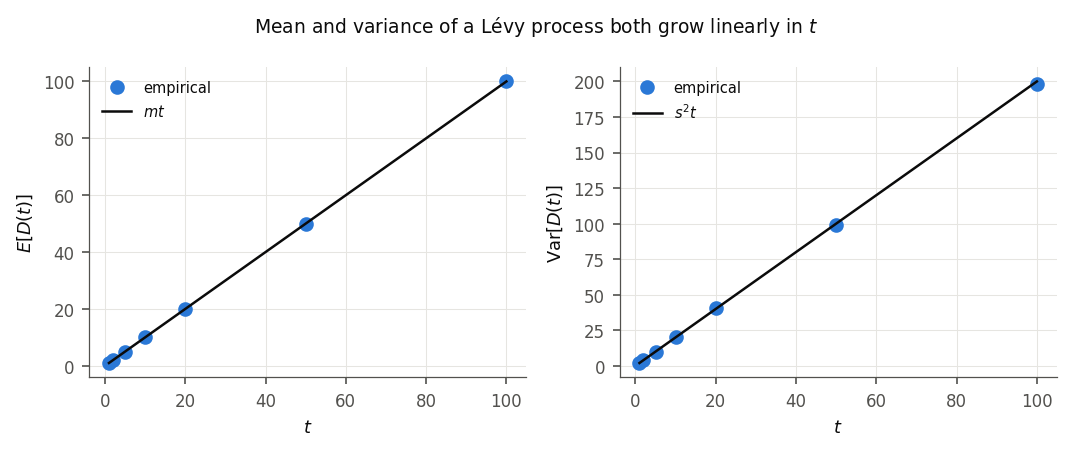

In [7]:
t_list = np.array([1.0, 2.0, 5.0, 10.0, 20.0, 50.0, 100.0])
n_mc = 20000
rng = np.random.default_rng(13)
emp_mean_t, emp_var_t = [], []
for T in t_list:
    n = rng.poisson(lam_demo * T, size=n_mc)
    # sum of n_i iid Exp(beta_demo) each -> use the fact that sum of Poisson(n) exponentials
    # is Gamma(n, beta_demo); draw directly for speed
    D_T = rng.gamma(np.maximum(n, 1), beta_demo) * (n > 0)
    emp_mean_t.append(D_T.mean())
    emp_var_t.append(D_T.var())

fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.0))
axes[0].plot(t_list, emp_mean_t, "o", color=COL["CPP"], label="empirical")
axes[0].plot(t_list, lam_demo * beta_demo * t_list, color=INK, lw=1.2, label=r"$mt$")
axes[0].set_xlabel("$t$"); axes[0].set_ylabel(r"$E[D(t)]$"); axes[0].legend(fontsize=7)
axes[1].plot(t_list, emp_var_t, "o", color=COL["CPP"], label="empirical")
axes[1].plot(t_list, lam_demo * 2 * beta_demo**2 * t_list, color=INK, lw=1.2, label=r"$s^2t$")
axes[1].set_xlabel("$t$"); axes[1].set_ylabel(r"$\mathrm{Var}[D(t)]$"); axes[1].legend(fontsize=7)
fig.suptitle("Mean and variance of a Lévy process both grow linearly in $t$", fontsize=9)
fig.tight_layout()
plt.show()

### B.2 LLN and CLT for Lévy processes

Exactly as in Part A, with $n\to t$:

- **LLN**: $D(t)/t \to m$ almost surely as $t\to\infty$.
- **CLT**: $(D(t)-mt)/(s\sqrt t) \to \mathcal N(0,1)$ in distribution as
  $t\to\infty$.

Both are shown below for the driftless compound-Poisson process.

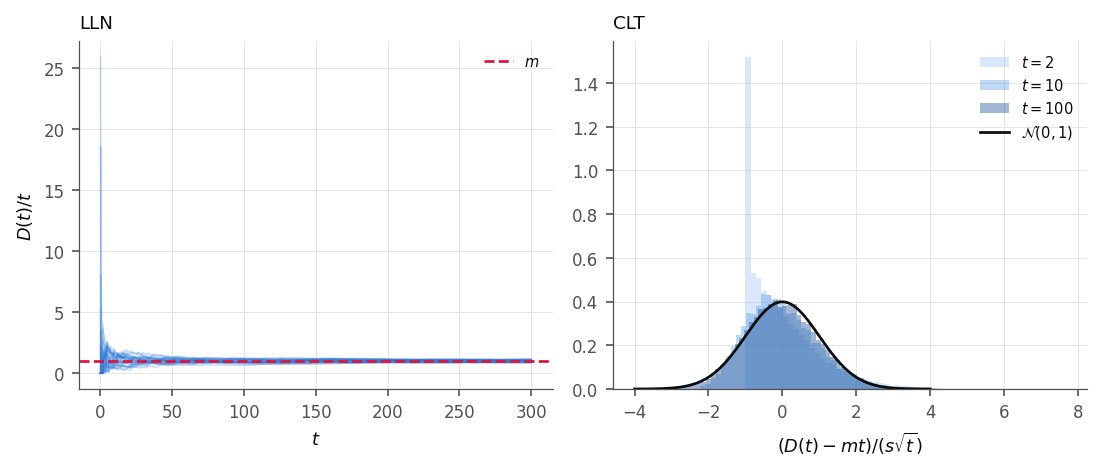

In [8]:
rng = np.random.default_rng(14)
T_max = 300.0
n_show = 25
n_fine = 3000
dt_fine = T_max / n_fine
# fine-grained CPP via many small Poisson-thinned steps (exact: Poisson process is itself
# infinitely divisible in time, so this is exact, not an approximation)
t_grid = np.arange(n_fine + 1) * dt_fine
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.2))
for _ in range(n_show):
    n = rng.poisson(lam_demo * T_max)
    arr = np.sort(rng.uniform(0, T_max, size=n))
    sz = rng.exponential(beta_demo, size=n)
    idx = np.searchsorted(arr, t_grid, side="right")
    y = np.concatenate(([0.0], np.cumsum(sz)))[idx]
    with np.errstate(divide="ignore", invalid="ignore"):
        ratio = np.where(t_grid > 0, y / t_grid, np.nan)
    axes[0].plot(t_grid, ratio, color=COL["CPP"], alpha=0.25, lw=0.8)
axes[0].axhline(lam_demo * beta_demo, color="crimson", ls="--", lw=1.3, label="$m$")
axes[0].set_xlabel("$t$"); axes[0].set_ylabel("$D(t)/t$")
axes[0].set_title("LLN", loc="left", fontsize=8.8); axes[0].legend(fontsize=7)

n_mc = 20000
m_demo, s_demo = lam_demo * beta_demo, np.sqrt(lam_demo * 2 * beta_demo**2)
for T, col in zip([2, 10, 100], ["#9ec5f0", "#5d9fe8", "#154a8f"]):
    n = rng.poisson(lam_demo * T, size=n_mc)
    D_T = rng.gamma(np.maximum(n, 1), beta_demo) * (n > 0)
    z = (D_T - m_demo * T) / (s_demo * np.sqrt(T))
    axes[1].hist(z, bins=60, density=True, alpha=0.4, color=col, label=f"$t={T}$")
xx = np.linspace(-4, 4, 200)
axes[1].plot(xx, stats.norm.pdf(xx), color=INK, lw=1.3, label=r"$\mathcal{N}(0,1)$")
axes[1].set_xlabel(r"$(D(t)-mt)/(s\sqrt{t})$")
axes[1].set_title("CLT", loc="left", fontsize=8.8); axes[1].legend(fontsize=7)
fig.tight_layout()
plt.show()

**Take-away from Part B:** nothing in the LLN/CLT machinery cared that we
moved from discrete $n$ to continuous $t$, or that the step law became a
genuine Lévy process rather than a simple i.i.d. sum — the mean and
variance are still linear, the LLN still gives a deterministic limit, and
the CLT still gives a universal Gaussian. What *will* matter, starting in
Part C, is restricting which Lévy processes are physically admissible for
a deposit that can only grow.

## Part C — Subordinators: the fouling case

A fouling deposit cannot un-deposit: $R(t)$, and the cumulative deposition
$D(t)$ feeding it, can only grow (Sec. I, assumption (c), non-negativity).
Among Part B's two example species, this immediately disqualifies one of
them.

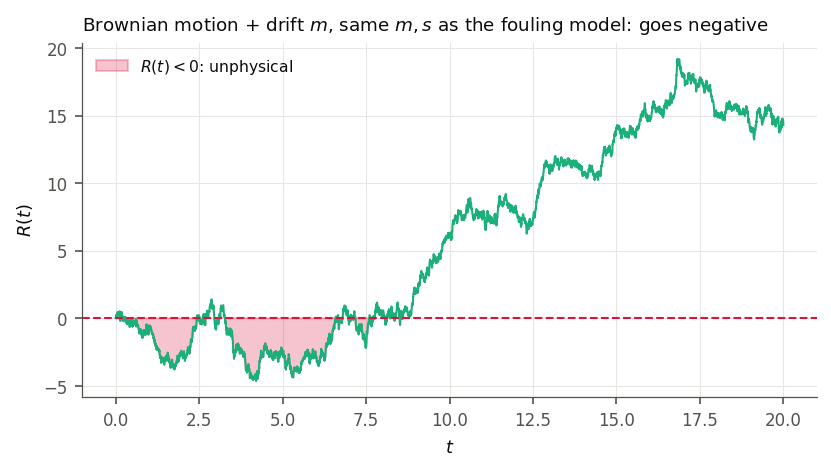

fraction of time below zero: 0.33891527118220444


In [9]:
rng = np.random.default_rng(1)
T_bm = 20.0
n_bm = 4000
dt_bm = T_bm / n_bm
bm_incr = rng.normal(0, s * np.sqrt(dt_bm), size=n_bm)
bm_path = np.concatenate(([0.0], np.cumsum(bm_incr))) + m * np.concatenate(([0.0], np.arange(1, n_bm + 1) * dt_bm))
t_bm = np.arange(n_bm + 1) * dt_bm

fig, ax = plt.subplots(figsize=(5.6, 3.2))
ax.plot(t_bm, bm_path, color=COL["BM"], lw=1.0)
ax.axhline(0, color="crimson", ls="--", lw=1.0)
below = bm_path < 0
if below.any():
    ax.fill_between(t_bm, bm_path, 0, where=below, color="crimson", alpha=0.25, label="$R(t)<0$: unphysical")
ax.set_xlabel("$t$"); ax.set_ylabel("$R(t)$")
ax.set_title("Brownian motion + drift $m$, same $m,s$ as the fouling model: goes negative", loc="left", fontsize=8.8)
ax.legend(fontsize=7.5)
fig.tight_layout()
plt.show()
print("fraction of time below zero:", np.mean(bm_path < 0))

However small its variance, a Gaussian increment is negative with
probability $1/2$: any Brownian component would, almost surely, make the
deposit shrink at some point with no removal mechanism at all. So the
Gaussian piece $\sigma^2$ of the general Lévy–Khintchine triplet
(Part B) is excluded **by the physics**, not by convenience. What remains
is the jump-type species, restricted further to upward jumps only:

**Definition.** A Lévy process with $\sigma^2=0$, no negative jumps, and
jump measure $\nu$ supported on $(0,\infty)$ is a **subordinator**: almost
surely non-decreasing. This is exactly what $D(t)$ represents in Sec. II.
Drift is still allowed ($b\ge0$ only, by the same argument), which is how
Sec. I's constant-rate pieces (e.g. the clean-surface deposition rate) sit
inside the same framework.

Not every non-negative random variable can be a subordinator's one-time
law, though: the Lévy–Khintchine construction requires it to be
**infinitely divisible** (every window, however short, must still look
like a sum of i.i.d. non-negative pieces from the same family). Compound
Poisson, Gamma and inverse Gaussian — the three laws of Sec. II.C — are
all infinitely divisible; a generic law such as Uniform(0,1) is not. A
classical necessary condition makes this concrete: the characteristic
function $\varphi(\theta)=\mathbb E[e^{i\theta X}]$ of an infinitely
divisible law can never be zero, while Uniform(0,1)'s
$\varphi(\theta)=(e^{i\theta}-1)/(i\theta)$ vanishes at
$\theta=2\pi,4\pi,\dots$

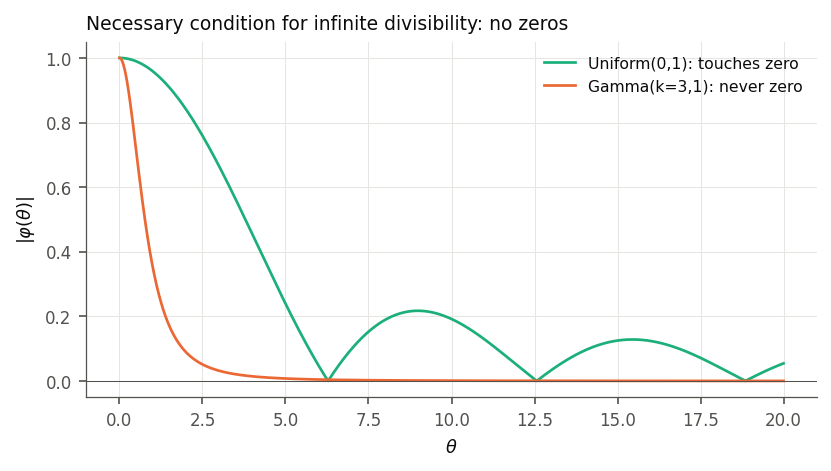

In [10]:
theta_grid = np.linspace(1e-3, 20, 3000)
phi_unif = np.where(theta_grid == 0, 1.0, (np.exp(1j * theta_grid) - 1) / (1j * theta_grid))
k_shape = 3.0
phi_gamma = (1 - 1j * theta_grid) ** (-k_shape)

fig, ax = plt.subplots(figsize=(5.6, 3.2))
ax.plot(theta_grid, np.abs(phi_unif), color=COL["BM"], lw=1.3, label="Uniform(0,1): touches zero")
ax.plot(theta_grid, np.abs(phi_gamma), color=COL["Gamma"], lw=1.3, label=f"Gamma(k={k_shape:.0f},1): never zero")
ax.axhline(0, color=INK2, lw=0.5)
ax.set_xlabel(r"$\theta$"); ax.set_ylabel(r"$|\varphi(\theta)|$")
ax.set_title("Necessary condition for infinite divisibility: no zeros", loc="left", fontsize=9)
ax.legend(fontsize=7.5)
fig.tight_layout()
plt.show()

### C.1 Activity: how many jumps are actually countable?

Within the subordinator family, the **activity** $r=\int_0^\infty\nu(x)\,dx$
(Sec. II, `sec:activity`) splits things further. Compound Poisson has
$r<\infty$: a genuine, finite, countable list of jumps. Gamma has
$r=\infty$: refine the time grid and count increments above a shrinking
threshold $\varepsilon$ — CPP's count saturates at the true (finite) jump
total, Gamma's keeps climbing without bound. (Full treatment, including
why this blocks a histogram of $\nu(x)$ for Gamma specifically, is in the
companion notebook `event_spectrum_cpp_vs_gamma.ipynb`.)

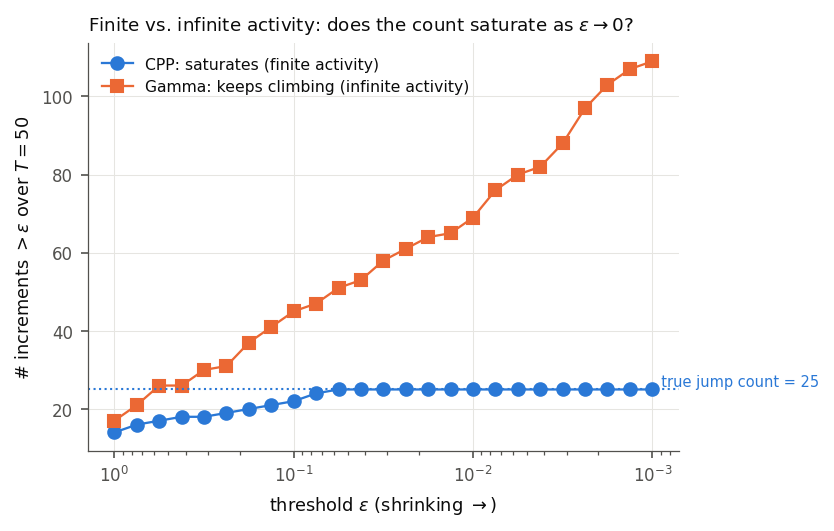

In [11]:
T_demo = 50.0
eps_grid = np.logspace(0, -3, 25)
rng = np.random.default_rng(5)
n_cpp = rng.poisson(lam_rate * T_demo)
cpp_jumps = rng.exponential(beta, size=n_cpp)
cpp_counts = [np.sum(cpp_jumps > e) for e in eps_grid]

n_fine = 400_000
dt_fine = T_demo / n_fine
shape_fine = dt_fine / c**2
gamma_incr = rng.gamma(shape_fine, theta_scale, size=n_fine)
gamma_counts = [np.sum(gamma_incr > e) for e in eps_grid]

fig, ax = plt.subplots(figsize=(5.6, 3.6))
ax.semilogx(eps_grid, cpp_counts, "o-", color=COL["CPP"], label="CPP: saturates (finite activity)")
ax.semilogx(eps_grid, gamma_counts, "s-", color=COL["Gamma"], label="Gamma: keeps climbing (infinite activity)")
ax.invert_xaxis()
ax.axhline(n_cpp, color=COL["CPP"], ls=":", lw=1.0)
ax.text(eps_grid[-1], n_cpp, f"  true jump count = {n_cpp}", color=COL["CPP"], fontsize=7, va="bottom")
ax.set_xlabel(r"threshold $\varepsilon$ (shrinking $\rightarrow$)")
ax.set_ylabel(rf"# increments $>\varepsilon$ over $T={T_demo:.0f}$")
ax.set_title("Finite vs. infinite activity: does the count saturate as $\\varepsilon\\to0$?", loc="left", fontsize=8.8)
ax.legend(fontsize=7.5)
fig.tight_layout()
plt.show()

## Part D — Building the expectation: what will the CLT do for fouling?

We now have everything needed to *predict* Sec. II.D's result before
looking at it.

From Part A/B, for any random walk or Lévy process with finite mean $m$
and variance rate $s^2$:
$$\frac{D(\Delta)-m\Delta}{s\sqrt\Delta}\;\xrightarrow{\ \Delta\to\infty\ }\;\mathcal N(0,1),$$
**universally**, regardless of the microscopic law — that was the whole
content of Parts A.3/B.2. Fouling deposition $D(\Delta)$ over a window
$\Delta$ is exactly this kind of object, a subordinator with finite $m,s^2$
(Part C). So the CLT *must* apply to it, for any of the three deposition
laws of Sec. II.C, as $\Delta$ grows — **before doing any fouling-specific
calculation at all**, universality alone already predicts that the three
laws become statistically indistinguishable once $\Delta$ is large enough.

The only fouling-specific question left is *how large is large enough* —
and Part A/C's own language already contains the answer: what matters is
not $\Delta$ in physical time units, but how many **size-biased events**
fit in it, $N_{\mathrm{eff}}=\Delta/t_c$ (Sec. II.A, `eq:neff`) — the direct
continuous-time analogue of Part A's step count $n$. The prediction is
therefore: *convergence to Gaussian should be controlled by
$N_{\mathrm{eff}}$, not by $\Delta$ itself*, and should proceed at the
standard CLT rate, skewness $\sim N_{\mathrm{eff}}^{-1/2}$ — exactly
Sec. II.D's Eq. `eq:cv_skew_scaling`/`eq:standardized_cumulants`
($\gamma_1(\Delta)\propto\Delta^{-1/2}$, since $N_{\mathrm{eff}}\propto\Delta$).
We check this prediction directly below, for the fouling model's own
compound-Poisson and Gamma laws.

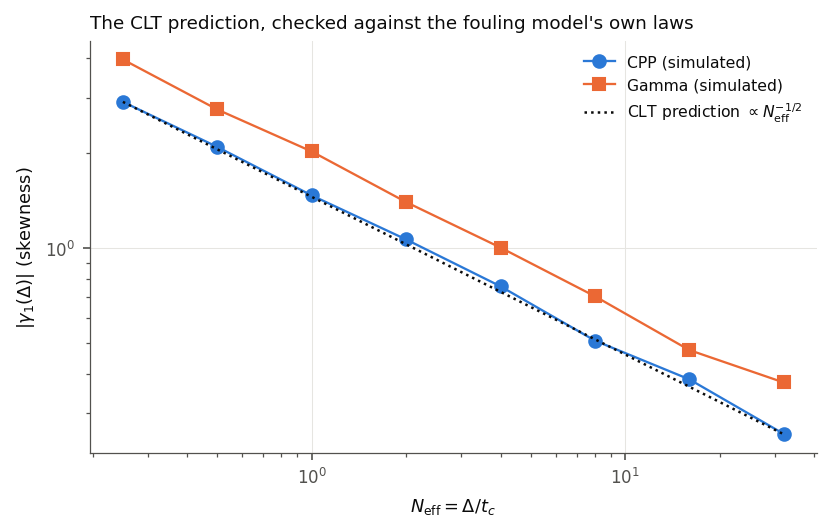

In [12]:
rng = np.random.default_rng(20)
Delta_list = np.array([tau0 * k for k in [1, 2, 4, 8, 16, 32, 64, 128]])
Neff_list = Delta_list / t_c
n_mc = 40000

def skew_cpp(Delta, n_mc, rng):
    n = rng.poisson(lam_rate * Delta, size=n_mc)
    D = rng.gamma(np.maximum(n, 1), beta) * (n > 0)
    return stats.skew(D)

def skew_gamma(Delta, n_mc, rng):
    shape = Delta / c**2
    D = rng.gamma(shape, theta_scale, size=n_mc)
    return stats.skew(D)

sk_cpp = [skew_cpp(D, n_mc, rng) for D in Delta_list]
sk_gamma = [skew_gamma(D, n_mc, rng) for D in Delta_list]

fig, ax = plt.subplots(figsize=(5.6, 3.6))
ax.loglog(Neff_list, np.abs(sk_cpp), "o-", color=COL["CPP"], label="CPP (simulated)")
ax.loglog(Neff_list, np.abs(sk_gamma), "s-", color=COL["Gamma"], label="Gamma (simulated)")
ref = np.abs(sk_cpp[0]) * (Neff_list / Neff_list[0]) ** (-0.5)
ax.loglog(Neff_list, ref, color=INK, ls=":", lw=1.2, label=r"CLT prediction $\propto N_{\mathrm{eff}}^{-1/2}$")
ax.set_xlabel(r"$N_{\mathrm{eff}}=\Delta/t_c$")
ax.set_ylabel(r"$|\gamma_1(\Delta)|$ (skewness)")
ax.set_title("The CLT prediction, checked against the fouling model's own laws", loc="left", fontsize=8.8)
ax.legend(fontsize=7.5)
fig.tight_layout()
plt.show()

The simulated skewness of both laws falls right along the predicted
$N_{\mathrm{eff}}^{-1/2}$ line — confirming, from first principles built up
in Parts A–C with no fouling-specific input, exactly the aggregation
behavior Sec. II.D derives and uses throughout the rest of the paper
(Sec. V's scale-separation and observability argument, Sec. VI's practical
consequences).

## Map: manuscript equations $\to$ which part they come from

| Manuscript location | Object | Part |
|---|---|---|
| Sec. I, `eq:deterministic_mass_balance`, `eq:kern_seaton_solution`, `eq:ebert_panchal_solution` | Deterministic mean curves | **A.2 / B.3**, LLN |
| Sec. II, `eq:stochastic_balance`, `eq:levy_khintchine` | The Lévy–Khintchine triplet, restricted to $\sigma^2=0$, $\nu$ on $(0,\infty)$ | **Part C**, subordinators |
| Sec. II, `eq:cumulant_rates`, `eq:deposition_mean`, `eq:deposition_variance_rate` | $\mathbb E[D(t)]=mt$, $\mathrm{Var}[D(t)]=s^2t$ | **A.1 / B.1**, linear mean & variance |
| Sec. II.A, `sec:activity`, `eq:ell`, `eq:neff` | Event spectrum $\nu(x)$, activity $r$, $N_{\mathrm{eff}}$ | **C.1**, activity |
| Sec. II.C, `sec:three_laws` | Compound Poisson / Gamma / inverse Gaussian | **Part C**, concrete infinitely divisible subordinators |
| Sec. II.D, `sec:aggregation` | Aggregation to Gaussian behavior at large $N_{\mathrm{eff}}$ | **Part D**, the CLT, predicted then checked |

## Recap

- **Part A**: a random walk's mean and variance grow linearly in the
  number of steps $n$; dividing by $n$ gives a deterministic LLN limit;
  standardizing by $\sqrt n$ gives a universal Gaussian CLT limit.
- **Part B**: a Lévy process is the same object with $n\to t$; drift only
  ever shifts the mean, never the fluctuation shape; mean/variance/LLN/CLT
  all carry over unchanged.
- **Part C**: fouling needs a **subordinator** — no Gaussian component
  (it would make the deposit shrink), only non-negative jumps, drawn from
  an infinitely divisible law; CPP and Gamma are both admissible, and
  differ in **activity** (finite vs. infinite).
- **Part D**: because fouling deposition is a subordinator with finite
  $m,s^2$, Part A/B's CLT applies to it *unconditionally* — the three
  laws of Sec. II.C must become statistically indistinguishable once the
  aggregation window $\Delta$ contains enough size-biased events
  ($N_{\mathrm{eff}}=\Delta/t_c\gg1$), at the standard
  $N_{\mathrm{eff}}^{-1/2}$ rate. This was predicted from general
  principles before being checked against the fouling model's own laws,
  and it matches.